# Predicting Bank Term-Deposit Subscriptions: Comparing Classifiers

**Module 17 – Practical Application III** | Data: UCI Bank Marketing (Moro, Cortez & Rita, 2014)

**Contents**
1. Business Understanding
2. Data Understanding
3. Data Cleaning & Preparation
4. Exploratory Data Analysis (descriptive & inferential statistics)
5. Modeling (baseline, default comparison, cross-validated grid search)
6. Interpreting the Models
7. Findings (for a non-technical audience)
8. Next Steps & Recommendations

## 1. Business Understanding

A Portuguese retail bank phones customers to sell a **long-term deposit** product. The dataset covers **17 telemarketing campaigns run between May 2008 and November 2010** (~41,000 calls).

**Business problem.** Calling is expensive and most calls fail: only about 1 in 9 customers subscribes. The bank wants to know **which customers are most likely to say "yes" so agents can spend their time on the right people**.

**Analytical goal.** Build and compare four classifiers (K-Nearest Neighbors, Logistic Regression, Decision Tree, Support Vector Machine) that predict `y` (subscribed: yes/no), and identify the characteristics that drive success.

**Evaluation metric.** Only ~11% of customers say yes, so *accuracy is misleading*: a model that always says "no" is ~89% accurate yet finds zero buyers. We therefore use:
- **F1-score of the "yes" class** (primary metric, also used to tune the models): it balances *precision* (of those we call, how many buy?) and *recall* (of all buyers, how many do we reach?). Both matter, since wasted calls cost money and missed buyers cost revenue.
- **ROC-AUC** (secondary): how well a model ranks buyers above non-buyers regardless of threshold.

**Leakage note.** `duration` (call length) is only known *after* the call ends, so it can't be used to decide whom to call. As the dataset's authors advise for realistic models, we **exclude it**.

## 2. Data Understanding

In [1]:
import warnings
import time

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

In [2]:
bank = pd.read_csv("data/bank-additional-full.csv", sep=";")
print(f"Rows: {bank.shape[0]:,} | Columns: {bank.shape[1]}")
bank.head()

Rows: 41,188 | Columns: 21


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
# Data types, non-null counts and number of distinct values per column
pd.DataFrame({"dtype": bank.dtypes, "missing": bank.isna().sum(), "unique": bank.nunique()})

,dtype,missing,unique
age,int64,0,78
job,str,0,12
marital,str,0,4
education,str,0,8
default,str,0,3
housing,str,0,3
loan,str,0,3
contact,str,0,2
month,str,0,10
day_of_week,str,0,5


**Observations**
- No `NaN`s, but several categorical columns use the text **"unknown"** for missing values (job, marital, education, default, housing, loan). We keep "unknown" as its own category: for `default` it is large and may itself be informative.
- `pdays` = 999 means *"client was never previously contacted"*, not 999 days. We convert this to a flag.
- Categorical columns are stored as `object` and will be one-hot encoded.

In [4]:
# How many 'unknown' values are in each categorical column?
categorical_cols = bank.select_dtypes(include="object").columns.drop("y")
(bank[categorical_cols] == "unknown").sum().loc[lambda s: s > 0].sort_values(ascending=False).to_frame("unknown_count")

,unknown_count
default,8597
education,1731
housing,990
loan,990
job,330
marital,80


## 3. Data Cleaning & Preparation

In [5]:
# 1) Remove exact duplicate rows
n_before = len(bank)
bank = bank.drop_duplicates().reset_index(drop=True)
print(f"Dropped {n_before - len(bank)} duplicate rows")

# 2) Convert pdays=999 ("never contacted") into a binary flag and a cleaner numeric column
bank["previously_contacted"] = (bank["pdays"] != 999).astype(int)
bank["pdays"] = bank["pdays"].replace(999, 0)

# 3) Encode target: yes -> 1, no -> 0
bank["subscribed"] = (bank["y"] == "yes").astype(int)

# 4) Drop 'duration' (known only after the call -> data leakage) and the raw target column
bank = bank.drop(columns=["duration", "y"])

print(f"Subscription rate: {bank['subscribed'].mean():.1%}")

Dropped 12 duplicate rows
Subscription rate: 11.3%


## 4. Exploratory Data Analysis

### 4.1 Target balance and key categorical drivers

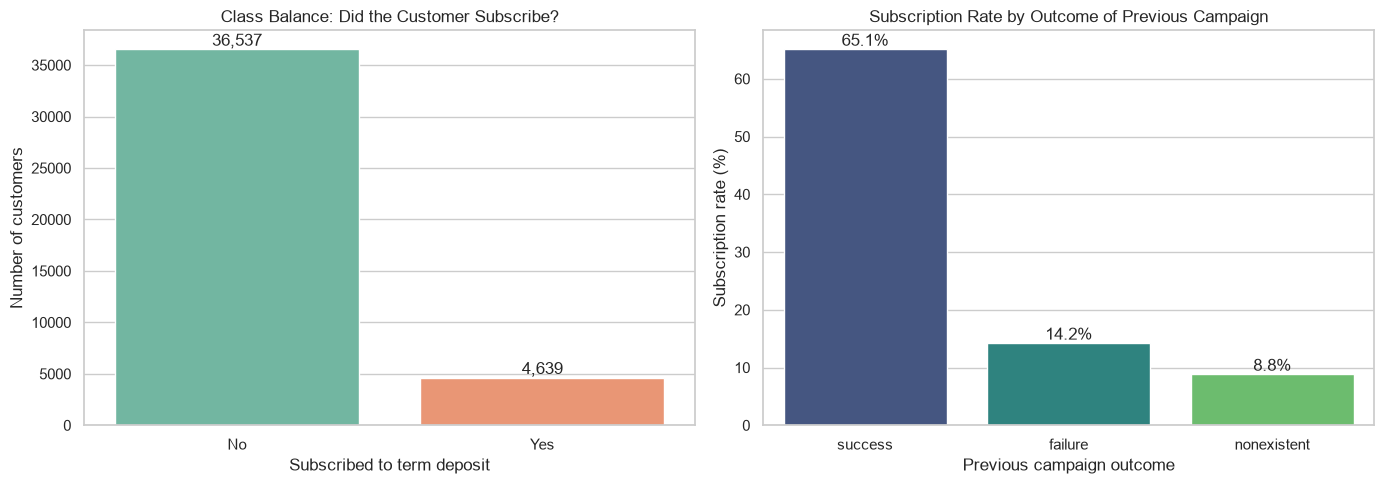

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Class balance
sns.countplot(data=bank, x="subscribed", hue="subscribed", palette="Set2", legend=False, ax=axes[0])
axes[0].set_xticks([0, 1], ["No", "Yes"])
axes[0].set_title("Class Balance: Did the Customer Subscribe?")
axes[0].set_xlabel("Subscribed to term deposit")
axes[0].set_ylabel("Number of customers")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="{:,.0f}")

# Success rate by previous campaign outcome
rate = bank.groupby("poutcome")["subscribed"].mean().sort_values(ascending=False).mul(100).reset_index()
sns.barplot(data=rate, x="poutcome", y="subscribed", hue="poutcome", palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("Subscription Rate by Outcome of Previous Campaign")
axes[1].set_xlabel("Previous campaign outcome")
axes[1].set_ylabel("Subscription rate (%)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.savefig("images/01_class_balance_and_poutcome.png", dpi=150, bbox_inches="tight")
plt.show()

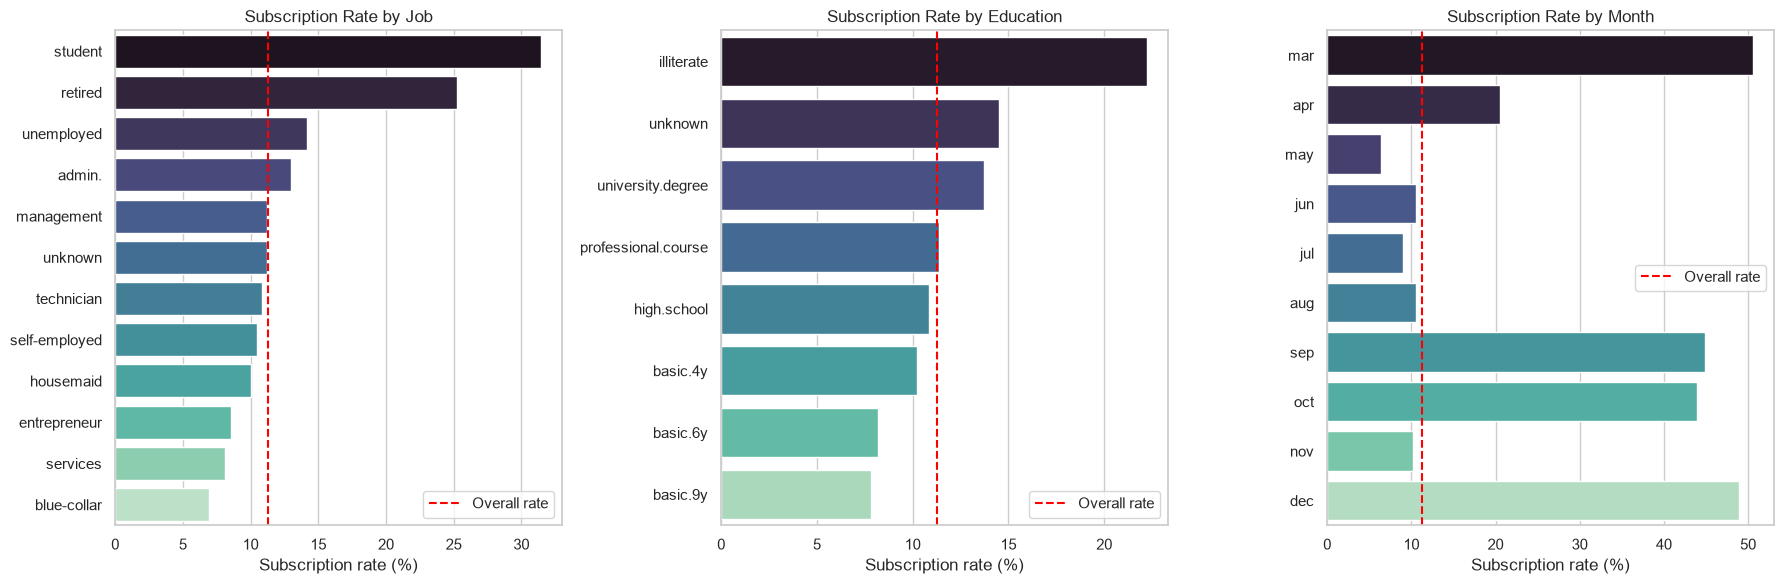

In [7]:
# Subscription rate by job, education, and contact month (horizontal bars keep long labels legible)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

for ax, col, order in zip(axes, ["job", "education", "month"], [None, None, month_order]):
    rate = bank.groupby(col)["subscribed"].mean().mul(100)
    rate = rate.loc[order] if order else rate.sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, hue=rate.index, palette="mako", legend=False, orient="h", ax=ax)
    ax.axvline(bank["subscribed"].mean() * 100, color="red", linestyle="--", label="Overall rate")
    ax.set_title(f"Subscription Rate by {col.title()}")
    ax.set_xlabel("Subscription rate (%)")
    ax.set_ylabel("")
    ax.legend()

plt.tight_layout()
plt.savefig("images/02_subscription_rate_by_job_education_month.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the charts**
- A **previous success** is by far the strongest signal (roughly two-thirds of those customers subscribe again versus ~9% for those with no history).
- **Students (31%) and retirees (25%)** subscribe at 2–3x the overall rate of 11% (red dashed line); blue-collar and services workers are below it.
- **March, September, October and December** have very high rates, but these are *low-volume* months. Most calls are in May, where the success rate is lowest.

### 4.2 Continuous variables

In [8]:
numeric_cols = ["age", "campaign", "pdays", "previous", "emp.var.rate",
                "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
bank[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
campaign,41176.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41176.0,0.22,1.35,0.00,0.00,0.00,0.00,27.00
previous,41176.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41176.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41176.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41176.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41176.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41176.0,5167.03,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


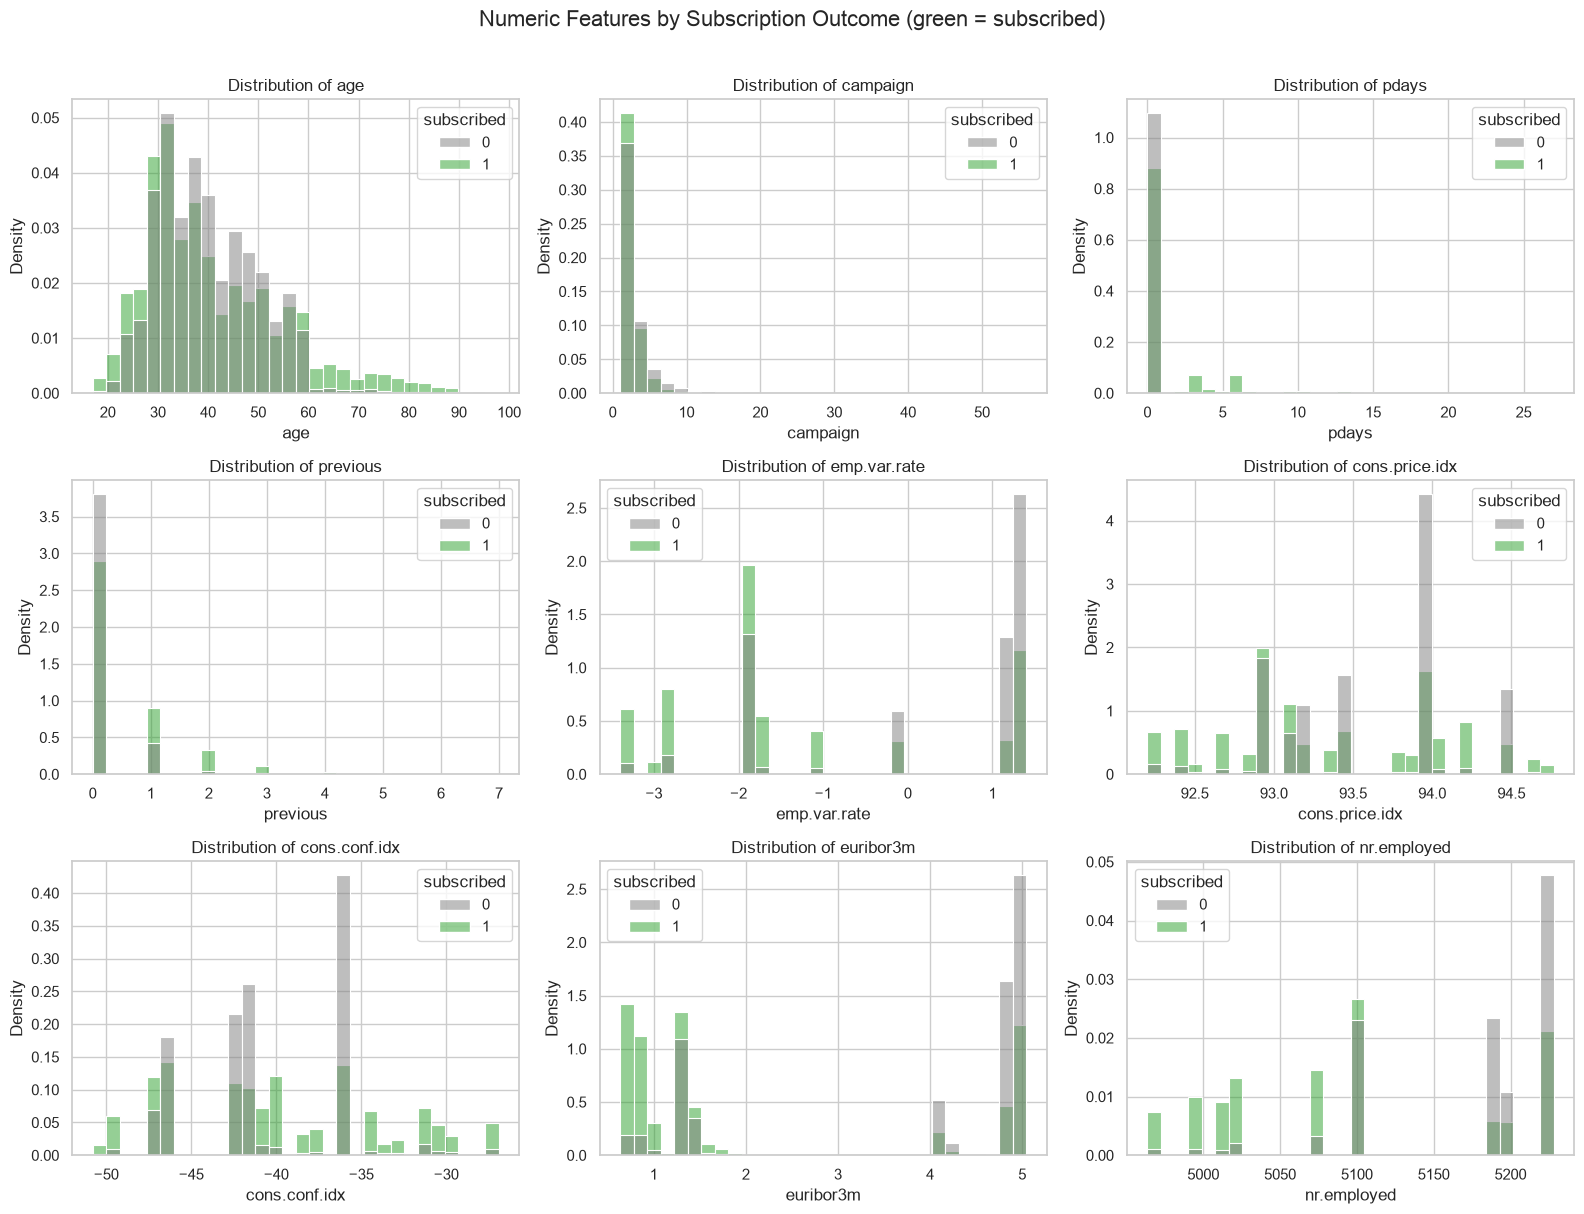

In [9]:
# Distribution of each numeric feature, split by outcome
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.histplot(data=bank, x=col, hue="subscribed", bins=30, stat="density", common_norm=False,
                 palette={0: "tab:gray", 1: "tab:green"}, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
fig.suptitle("Numeric Features by Subscription Outcome (green = subscribed)", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig("images/03_numeric_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

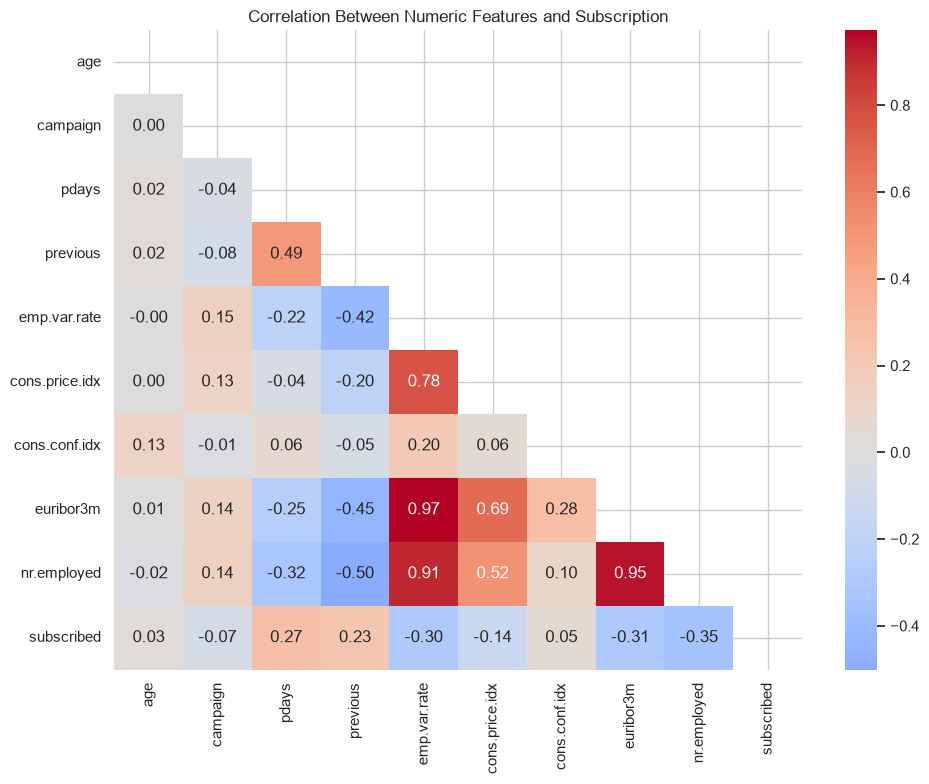

In [10]:
# Correlation heatmap of numeric features and the target
plt.figure(figsize=(10, 8))
corr = bank[numeric_cols + ["subscribed"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=np.triu(np.ones_like(corr, dtype=bool)))
plt.title("Correlation Between Numeric Features and Subscription")
plt.tight_layout()
plt.savefig("images/04_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the charts**
- Subscribers are concentrated in **low interest-rate / low-employment-rate periods**: average `euribor3m` is 2.1 for subscribers vs 3.8 for non-subscribers. Customers appear more receptive to a deposit offer when market rates are falling.
- `euribor3m`, `emp.var.rate` and `nr.employed` are **highly correlated (≈0.9+)** with each other. This is multicollinearity: it doesn't hurt prediction much, but it makes individual logistic-regression coefficients for these three unstable to interpret.
- `age` has a long right tail and `campaign` is heavily skewed (a few customers were called 20–50 times), motivating scaling before KNN/SVM.

### 4.3 Inferential statistics

We test whether each feature is **statistically associated** with subscription (α = 0.05):
- **Continuous features**: Welch's t-test comparing subscribers vs non-subscribers (robust to unequal variances; very large n makes the CLT appropriate).
- **Categorical features**: chi-square test of independence, with **Cramér's V** as an effect size (0 = none, 1 = perfect), because with ~40k rows nearly everything is "significant" and effect size shows what actually matters.

In [11]:
# Welch t-tests for numeric features
yes, no = bank[bank["subscribed"] == 1], bank[bank["subscribed"] == 0]
ttest_rows = []
for col in numeric_cols:
    t_stat, p_val = stats.ttest_ind(yes[col], no[col], equal_var=False)
    ttest_rows.append({"feature": col, "mean_subscribed": yes[col].mean(), "mean_not_subscribed": no[col].mean(),
                       "t_statistic": t_stat, "p_value": p_val})
ttest_df = pd.DataFrame(ttest_rows).set_index("feature").round(4)

# Chi-square tests + Cramér's V for categorical features
chi_rows = []
for col in categorical_cols:
    table = pd.crosstab(bank[col], bank["subscribed"])
    chi2, p_val, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    chi_rows.append({"feature": col, "chi2": chi2, "p_value": p_val, "cramers_v": cramers_v})
chi_df = pd.DataFrame(chi_rows).set_index("feature").sort_values("cramers_v", ascending=False).round(4)

display(ttest_df)
display(chi_df)

,mean_subscribed,mean_not_subscribed,t_statistic,p_value
feature,,,,
age,40.9123,39.9110,4.7753,0.0
campaign,2.0520,2.6334,-20.2479,0.0
pdays,1.2326,0.0929,26.2165,0.0
previous,0.4928,0.1324,28.1256,0.0
emp.var.rate,-1.2331,0.2489,-59.1166,0.0
cons.price.idx,93.3546,93.6038,-24.0670,0.0
cons.conf.idx,-39.7911,-40.5932,8.6227,0.0
euribor3m,2.1234,3.8115,-62.5603,0.0
nr.employed,5095.1201,5176.1657,-60.9589,0.0


,chi2,p_value,cramers_v
feature,,,
poutcome,4230.1434,0.0000,0.3205
month,3103.0327,0.0000,0.2745
job,961.7438,0.0000,0.1528
contact,862.0807,0.0000,0.1447
default,406.5561,0.0000,0.0994
education,192.8485,0.0000,0.0684
marital,122.9593,0.0000,0.0546
day_of_week,26.0542,0.0000,0.0252
housing,5.7422,0.0566,0.0118


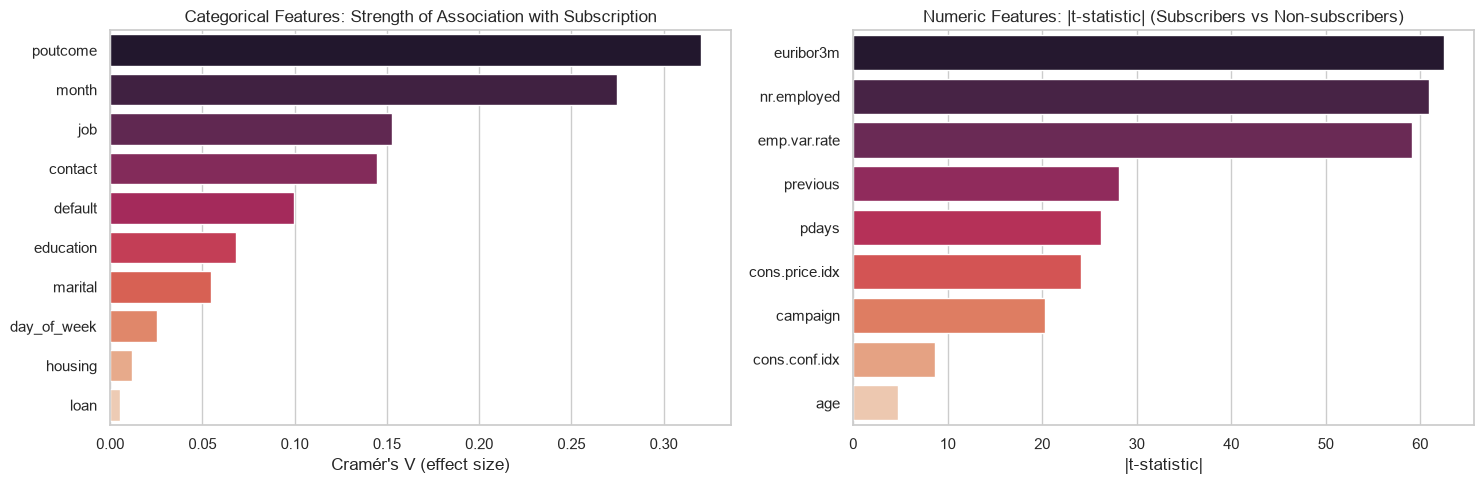

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=chi_df["cramers_v"], y=chi_df.index, hue=chi_df.index, palette="rocket", legend=False, ax=axes[0])
axes[0].set_title("Categorical Features: Strength of Association with Subscription")
axes[0].set_xlabel("Cramér's V (effect size)")
axes[0].set_ylabel("")

t_abs = ttest_df["t_statistic"].abs().sort_values(ascending=False)
sns.barplot(x=t_abs.values, y=t_abs.index, hue=t_abs.index, palette="rocket", legend=False, ax=axes[1])
axes[1].set_title("Numeric Features: |t-statistic| (Subscribers vs Non-subscribers)")
axes[1].set_xlabel("|t-statistic|")
axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig("images/05_inferential_effect_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation.** Almost every feature is statistically significant (p < 0.05), which is expected with ~40,000 rows, so we rely on effect sizes. The strongest relationships are with **`poutcome`, `month`, and `contact` type** (categorical) and with the **macro-economic indicators (`euribor3m`, `nr.employed`, `emp.var.rate`; |t| ≈ 60) and `previous`/`pdays`** (numeric). Demographics such as `marital` and `housing`/`loan` have small effect sizes, so they carry little predictive information. `loan` (p = 0.58) and `housing` (p = 0.06) are not statistically significant at α = 0.05.

## 5. Modeling

### 5.1 Train/test split and preprocessing

In [13]:
X = bank.drop(columns="subscribed")
y = bank["subscribed"]

# Stratify so train and test keep the same ~11% subscription rate
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows")
print(f"Subscription rate  train: {y_train.mean():.2%}  test: {y_test.mean():.2%}")

# Scale numeric columns (needed by KNN/SVM/LogReg) and one-hot encode categoricals.
# Wrapped in a ColumnTransformer inside each Pipeline so scaling is fit only on training folds (no leakage in CV).
num_features = X.select_dtypes(exclude="object").columns.tolist()
cat_features = X.select_dtypes(include="object").columns.tolist()
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_features),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: 30,882 rows | Test: 10,294 rows
Subscription rate  train: 11.27%  test: 11.27%


### 5.2 Baseline
The baseline is a classifier that always predicts the majority class ("no"). Any real model must beat it **on F1/ROC-AUC**; its accuracy is high but it finds zero buyers.

In [14]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred = baseline.predict(X_test)
print(f"Baseline accuracy: {accuracy_score(y_test, pred):.3f}")
print(f"Baseline F1 (yes class): {f1_score(y_test, pred):.3f}  <- finds no buyers at all")

Baseline accuracy: 0.887
Baseline F1 (yes class): 0.000  <- finds no buyers at all


### 5.3 Default-settings comparison (5-fold cross-validation)
We first compare all four models with default hyperparameters, using stratified 5-fold CV on the training set to get a stable estimate. The test set is untouched.

In [15]:
default_models = {
    "KNN": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(random_state=RANDOM_STATE),
}

rows = []
for name, model in default_models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", model)])
    start = time.time()
    f1_cv = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    auc_cv = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    acc_cv = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    rows.append({"model": name, "cv_accuracy": acc_cv.mean(), "cv_f1": f1_cv.mean(),
                 "cv_f1_std": f1_cv.std(), "cv_roc_auc": auc_cv.mean(), "seconds": time.time() - start})
default_results = pd.DataFrame(rows).set_index("model").round(3)
default_results

,cv_accuracy,cv_f1,cv_f1_std,cv_roc_auc,seconds
model,,,,,
KNN,0.890,0.365,0.014,0.722,6.441
Logistic Regression,0.900,0.344,0.012,0.788,2.106
Decision Tree,0.841,0.322,0.017,0.622,0.838
SVM (RBF),0.900,0.339,0.006,0.702,119.470


Default models have high accuracy (0.84–0.90) yet low F1 (0.32–0.37): they mostly predict "no" because "yes" is rare. This is why we tune on **F1** and rebalance classes in the next step.

### 5.4 Hyperparameter tuning with cross-validated grid search
Each model is tuned with `GridSearchCV` (5-fold, **scoring = F1**). We include `class_weight="balanced"` as a hyperparameter for the models that support it, so the search can choose to penalize missed buyers more heavily. The SVM grid is searched on a stratified 8,000-row subsample for speed (RBF SVMs scale poorly), then the best configuration is refit on the full training set.

In [16]:
search_spaces = {
    "KNN": (KNeighborsClassifier(),
            {"clf__n_neighbors": [5, 15, 31, 51], "clf__weights": ["uniform", "distance"]}),
    "Logistic Regression": (LogisticRegression(max_iter=2000),
            {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
            {"clf__max_depth": [3, 5, 7, 10], "clf__min_samples_leaf": [10, 50, 100],
             "clf__class_weight": [None, "balanced"]}),
    "SVM (RBF)": (SVC(probability=False, random_state=RANDOM_STATE),
            {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01], "clf__class_weight": [None, "balanced"]}),
}

# Stratified subsample used only for the SVM grid search
X_svm, _, y_svm, _ = train_test_split(X_train, y_train, train_size=8000, stratify=y_train, random_state=RANDOM_STATE)

best_models, tuning_rows = {}, []
for name, (model, grid) in search_spaces.items():
    pipe = Pipeline([("prep", preprocess), ("clf", model)])
    search = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1)
    X_fit, y_fit = (X_svm, y_svm) if name == "SVM (RBF)" else (X_train, y_train)
    start = time.time()
    search.fit(X_fit, y_fit)
    if name == "SVM (RBF)":      # refit best config on the full training set
        search.best_estimator_.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    tuning_rows.append({"model": name, "best_cv_f1": search.best_score_,
                        "best_params": {k.replace("clf__", ""): v for k, v in search.best_params_.items()},
                        "search_seconds": time.time() - start})
pd.DataFrame(tuning_rows).set_index("model").round(3)

,best_cv_f1,best_params,search_seconds
model,,,
KNN,0.365,"{'n_neighbors': 5, 'weights': 'uniform'}",4.397
Logistic Regression,0.453,"{'C': 10, 'class_weight': 'balanced'}",1.416
Decision Tree,0.462,"{'class_weight': 'balanced', 'max_depth': 10, ...",2.166
SVM (RBF),0.456,"{'C': 1, 'class_weight': 'balanced', 'gamma': ...",48.379


### 5.5 Final evaluation on the held-out test set

In [17]:
rows, test_scores = [], {}
for name, model in best_models.items():
    pred = model.predict(X_test)
    # decision_function / predict_proba give a continuous score for ROC-AUC
    score = model.decision_function(X_test) if hasattr(model, "decision_function") else model.predict_proba(X_test)[:, 1]
    test_scores[name] = score
    rows.append({"model": name, "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
                 "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, score)})
test_results = pd.DataFrame(rows).set_index("model").round(3).sort_values("f1", ascending=False)
test_results

,accuracy,precision,recall,f1,roc_auc
model,,,,,
SVM (RBF),0.855,0.407,0.633,0.495,0.786
Decision Tree,0.843,0.380,0.628,0.473,0.804
Logistic Regression,0.833,0.364,0.640,0.464,0.802
KNN,0.893,0.546,0.278,0.369,0.737


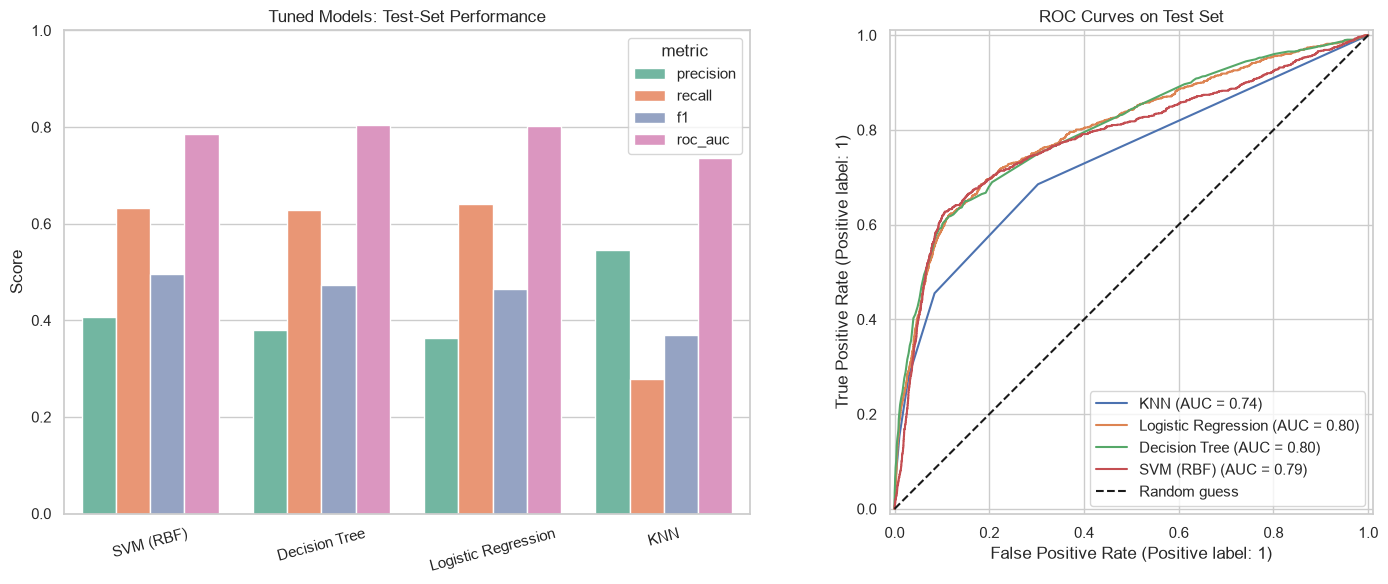

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: grouped metric bars
plot_df = test_results[["precision", "recall", "f1", "roc_auc"]].reset_index().melt(id_vars="model", var_name="metric", value_name="score")
sns.barplot(data=plot_df, x="model", y="score", hue="metric", palette="Set2", ax=axes[0])
axes[0].set_title("Tuned Models: Test-Set Performance")
axes[0].set_xlabel("")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=15)

# Right: ROC curves
for name, score in test_scores.items():
    RocCurveDisplay.from_predictions(y_test, score, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("ROC Curves on Test Set")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig("images/06_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

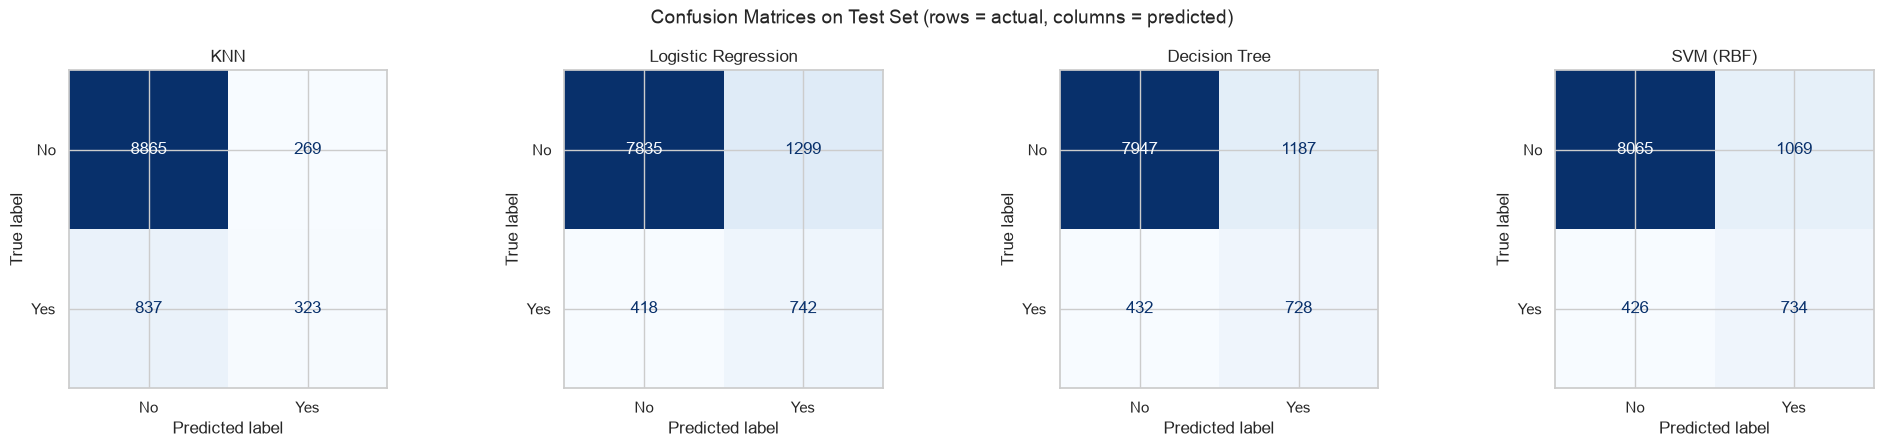

In [19]:
# Confusion matrices for all four tuned models
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["No", "Yes"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
fig.suptitle("Confusion Matrices on Test Set (rows = actual, columns = predicted)", fontsize=14)
plt.tight_layout()
plt.savefig("images/07_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Interpreting the Models

### 6.1 Logistic regression coefficients
Features were standardized, so numeric coefficients are comparable: the **odds ratio** `exp(coef)` is the multiplicative change in the odds of subscribing for a **1-standard-deviation increase** (numeric) or for the category versus its reference (one-hot). Odds ratio > 1 raises the chance of "yes"; < 1 lowers it.

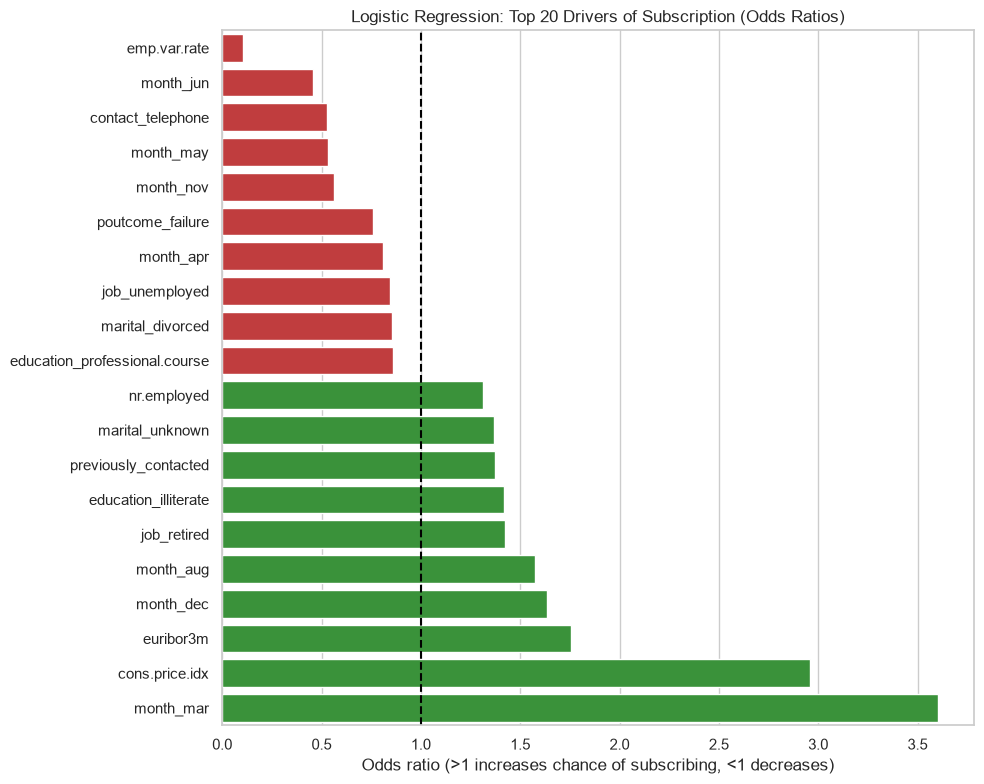

,coefficient,odds_ratio
month_mar,1.28,3.60
cons.price.idx,1.08,2.96
euribor3m,0.56,1.76
month_dec,0.49,1.63
month_aug,0.45,1.57
job_retired,0.35,1.42
education_illiterate,0.35,1.42
marital_unknown,0.31,1.37
previously_contacted,0.32,1.37
nr.employed,0.27,1.32


In [20]:
logreg = best_models["Logistic Regression"]
feature_names = logreg.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logreg.named_steps["clf"].coef_[0], index=feature_names)
coefs.index = coefs.index.str.replace("num__", "").str.replace("cat__", "")
top = pd.concat([coefs.nsmallest(10), coefs.nlargest(10)]).sort_values()
odds = np.exp(top)

plt.figure(figsize=(10, 8))
sns.barplot(x=odds.values, y=odds.index, hue=(odds.values > 1), palette={True: "tab:green", False: "tab:red"}, legend=False)
plt.axvline(1, color="black", linestyle="--")
plt.title("Logistic Regression: Top 20 Drivers of Subscription (Odds Ratios)")
plt.xlabel("Odds ratio (>1 increases chance of subscribing, <1 decreases)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("images/08_logistic_odds_ratios.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({"coefficient": top, "odds_ratio": odds}).round(2).sort_values("odds_ratio", ascending=False)

### 6.2 Decision tree
The tuned tree's feature importances show which variables drive its splits, and a shallow depth-3 tree shows the actual rules in plain terms.

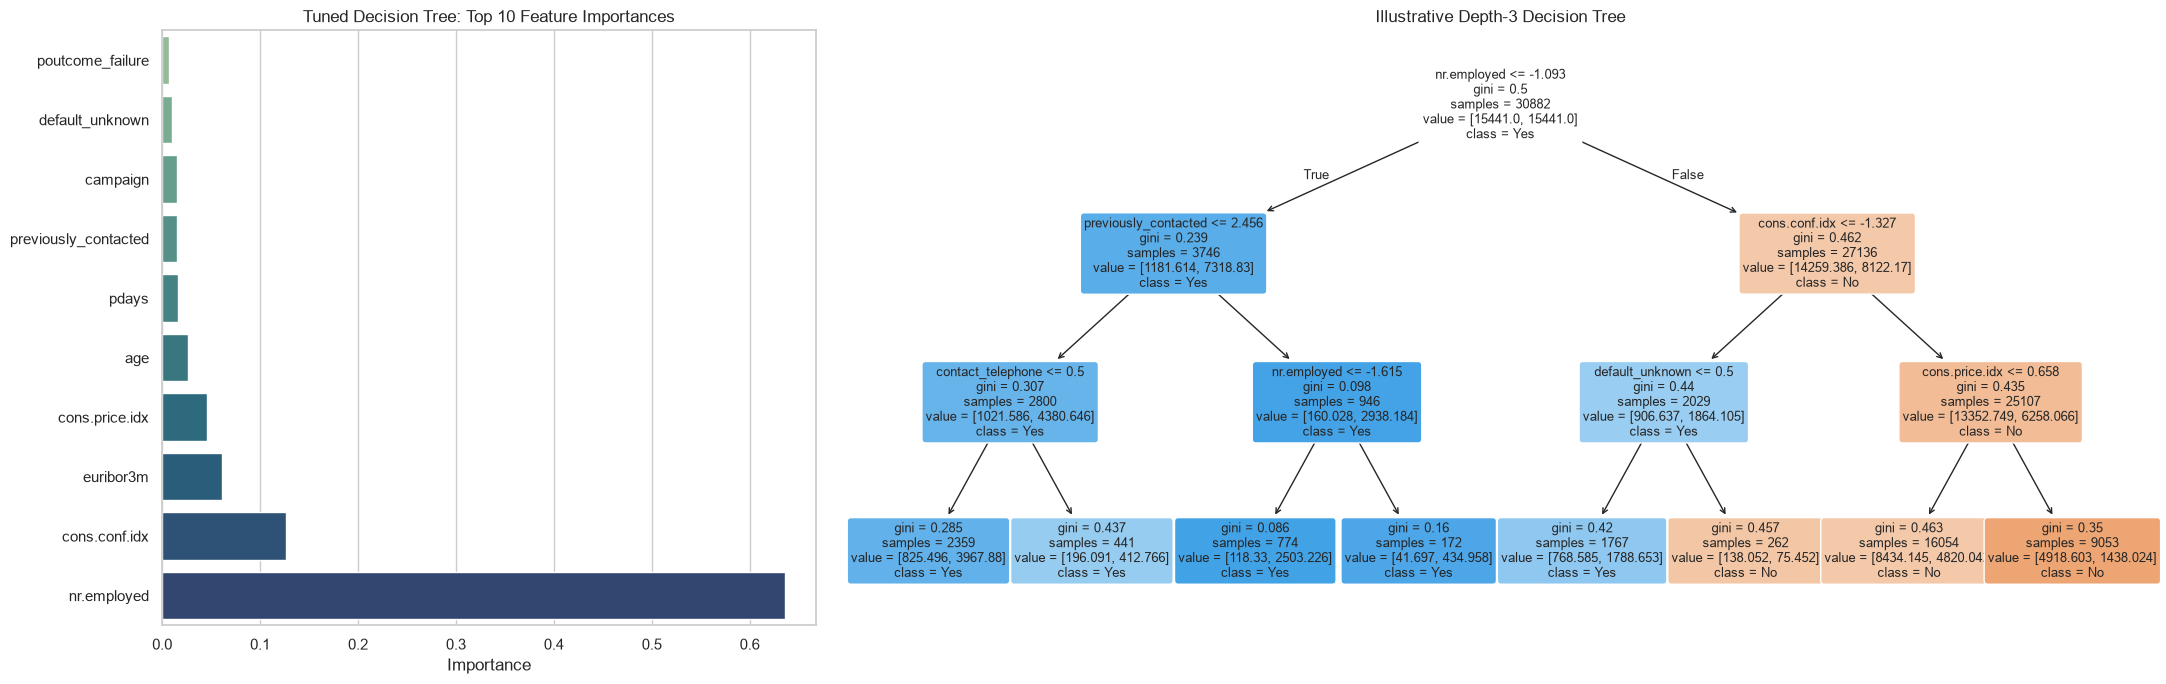

In [21]:
tree_pipe = best_models["Decision Tree"]
importances = pd.Series(tree_pipe.named_steps["clf"].feature_importances_, index=feature_names)
importances.index = importances.index.str.replace("num__", "").str.replace("cat__", "")
importances = importances.nlargest(10).sort_values()

# Illustrative shallow tree (depth 3) for readability
shallow = Pipeline([("prep", preprocess), ("clf", DecisionTreeClassifier(max_depth=3, min_samples_leaf=100,
                                                                           class_weight="balanced", random_state=RANDOM_STATE))])
shallow.fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(22, 7), gridspec_kw={"width_ratios": [1, 2]})
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette="crest", legend=False, ax=axes[0])
axes[0].set_title("Tuned Decision Tree: Top 10 Feature Importances")
axes[0].set_xlabel("Importance")
axes[0].set_ylabel("")
plot_tree(shallow.named_steps["clf"], feature_names=[n.split("__")[-1] for n in feature_names],
          class_names=["No", "Yes"], filled=True, rounded=True, fontsize=9, ax=axes[1])
axes[1].set_title("Illustrative Depth-3 Decision Tree")
plt.tight_layout()
plt.savefig("images/09_decision_tree.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.3 Business value: how many buyers do we reach by calling fewer people?
A **lift / gains** view translates model scores into call-center terms: if agents call only the top-scoring customers, what share of all buyers do they reach?

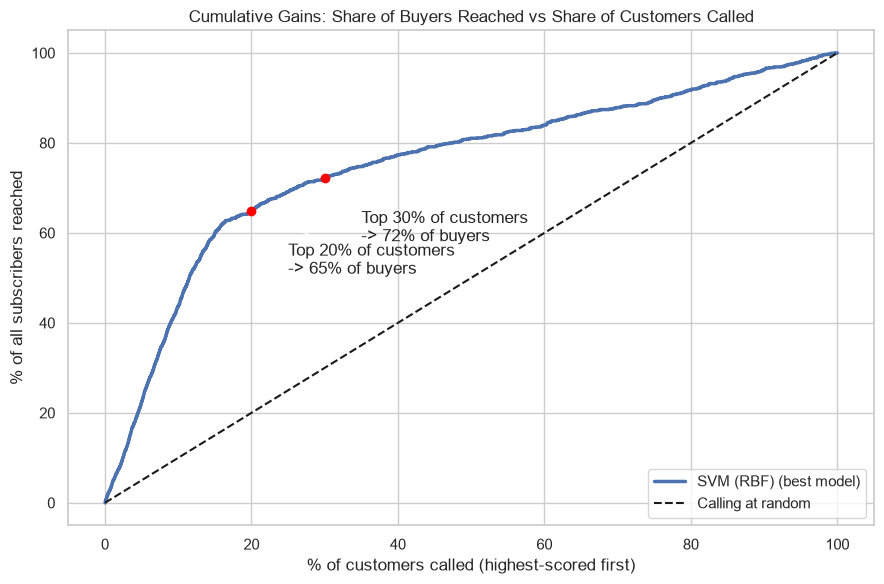

In [22]:
best_name = test_results["f1"].idxmax()
gain_df = pd.DataFrame({"score": test_scores[best_name], "actual": y_test.values}).sort_values("score", ascending=False)
gain_df["pct_contacted"] = np.arange(1, len(gain_df) + 1) / len(gain_df) * 100
gain_df["pct_buyers_reached"] = gain_df["actual"].cumsum() / gain_df["actual"].sum() * 100

plt.figure(figsize=(9, 6))
sns.lineplot(data=gain_df, x="pct_contacted", y="pct_buyers_reached", label=f"{best_name} (best model)", linewidth=2.5)
plt.plot([0, 100], [0, 100], "k--", label="Calling at random")
for pct in (20, 30):
    reached = gain_df.loc[gain_df["pct_contacted"] >= pct, "pct_buyers_reached"].iloc[0]
    plt.scatter([pct], [reached], color="red", zorder=5)
    plt.annotate(f"Top {pct}% of customers\n-> {reached:.0f}% of buyers", (pct, reached), xytext=(pct + 5, reached - 14),
                 arrowprops={"arrowstyle": "->"})
plt.title("Cumulative Gains: Share of Buyers Reached vs Share of Customers Called")
plt.xlabel("% of customers called (highest-scored first)")
plt.ylabel("% of all subscribers reached")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("images/10_cumulative_gains.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Findings (for a non-technical audience)

**Bottom line:** the bank can reach roughly **two-thirds of all likely subscribers by calling only the top 20% of customers** ranked by our model, instead of calling everyone. Calling at random would reach only 20% of subscribers with the same effort.

**How well do the models work?** (held-out test set, 10,294 customers, ~11% of whom subscribe)

| Model | F1 ("yes") | Recall | Precision | ROC-AUC |
|---|---|---|---|---|
| SVM (RBF) | **0.495** | 0.63 | 0.41 | 0.79 |
| Decision Tree | 0.473 | 0.63 | 0.38 | **0.80** |
| Logistic Regression | 0.464 | 0.64 | 0.36 | **0.80** |
| KNN | 0.369 | 0.28 | 0.55 | 0.74 |
| *Baseline (always "no")* | *0.000* | *0* | *n/a* | *0.50* |

- **Three models are close**; the SVM wins narrowly on F1, but the decision tree and logistic regression are far faster, simpler, and explainable, so they are the practical choice. KNN is clearly weakest: it is too cautious and misses ~72% of buyers.
- **Tuning matters.** With default settings every model scored F1 of only 0.32–0.37. Cross-validated tuning plus re-weighting the rare "yes" class lifted the top three to 0.46–0.50 and lets them catch ~63% of buyers, at the cost of lower raw accuracy (0.83–0.86 vs 0.89 for "always no"). Accuracy alone would have wrongly favored the useless baseline.
- **Honest limits.** Precision is about 36–41%: even among customers the model flags, most still say no. The model prioritizes calls; it does not guarantee a sale.

**What drives a "yes"?**

| Insight | Evidence | Actionable? |
|---|---|---|
| **Past successes re-subscribe** | 65% success rate for previous-campaign successes vs 9% for first-time contacts | **Yes: call these customers first** |
| **Mobile beats landline** | 14.7% success on cellular vs 5.2% on telephone; odds ratio 0.53 for landline | **Yes: prioritize cellular contacts** |
| **Students and retirees** | 31% and 25% success vs 11% overall; blue-collar only 7% | **Yes: target these segments** |
| **Timing** | March, September, October, December convert at 44–51%, but are low-volume; May, the busiest month, converts at only 6.4% | **Yes: shift effort into high-yield months** |
| **Economy** | Subscribers cluster when interest rates / `euribor3m` are low (avg 2.1 vs 3.8) | Plan campaigns around rate cycles |
| **Not useful** | Having a housing or personal loan shows no significant relationship | Don't segment on this |

*Note on timing:* May alone holds about a third of all calls (13,767 of 41,176) but has the lowest success rate (6.4%). Months with half the success rate also have very few calls, so part of that pattern may reflect *who* was called, not the month itself.

*Statistical caution:* the logistic-regression odds ratios for the three correlated economic indicators (`euribor3m`, `emp.var.rate`, `nr.employed`) are not individually reliable because they move together; interpret them as one "economic climate" signal. Results show association, not proof of cause.

## 8. Next Steps & Recommendations

**Recommendations for the business**
1. **Prioritize the call list with the model.** Rank customers by predicted likelihood and work from the top: the top 20% reaches ~65% of subscribers, the top 30% about 72%.
2. **Start with the sure bets:** previous-campaign successes, students, and retirees, reached on cellular phones.
3. **Re-balance campaign timing** toward the higher-yield months (March, September–December) and test the effect with a controlled pilot rather than assuming it.
4. **Cap repeat attempts.** Subscribers averaged 2.1 contact attempts vs 2.6 for non-subscribers, so repeated calling has diminishing returns.

**Next steps for the data team**
1. **Pilot test (A/B)**: model-ranked list vs. current practice, to confirm real-world lift and measure cost per subscription.
2. **Choose the threshold by cost.** Set the decision cutoff using the actual cost of a call vs. the profit from a deposit, rather than F1 alone.
3. **Improve the models:** try gradient-boosted trees, probability calibration, and richer features (account balance, tenure, product holdings).
4. **Check data drift.** The data covers 2008–2010 during the financial crisis; retrain on recent campaigns before use.
5. **Monitor fairness.** Age and job are predictive, so audit that targeting does not systematically exclude groups unfairly.